In [2]:
import pandas as pd
import numpy as np
import json
from pathlib import Path

# Rutas relativas desde la carpeta /code hacia /data
DATA_DIR = Path("../data")
csv_path = DATA_DIR / "GBvideos_cc50_202101.csv"
json_path = DATA_DIR / "GB_category_id.json"

# Carga del CSV y JSON
df = pd.read_csv(csv_path)
with open(json_path, "r", encoding="utf-8") as f:
    cat_json = json.load(f)

# Mapeo de categorías del JSON
categorias = {int(item["id"]): item["snippet"]["title"] for item in cat_json["items"]}

print("=== 1. DIMENSIONES ===")
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
print("\n=== 2. COLUMNAS Y TIPOS ===")
print(df.dtypes)

print("\n=== 3. VIDEOS ÚNICOS VS REGISTROS ===")
total_filas = len(df)
videos_unicos = df["video_id"].nunique()
duplicados_exactos = df.duplicated().sum()
duplicados_video_fecha = df.duplicated(subset=["video_id", "trending_date"]).sum()
print(f"Total de filas: {total_filas:,}")
print(f"Videos únicos (video_id): {videos_unicos:,}")
print(f"Duplicados exactos (toda la fila): {duplicados_exactos:,}")
print(f"Duplicados (mismo video_id + misma trending_date): {duplicados_video_fecha:,}")

print("\n=== 4. VALORES FALTANTES (NULOS) ===")
nulos = df.isnull().sum()
print(nulos[nulos > 0] if nulos.sum() > 0 else "No hay valores nulos.")

print("\n=== 5. RANGO DE FECHAS ===")
print("Muestra trending_date:", df["trending_date"].head(3).tolist())
print("Muestra publish_time:", df["publish_time"].head(3).tolist())
fechas_trend = pd.to_datetime(df["trending_date"], format="%y.%d.%m", errors="coerce")
print(f"trending_date -> Min: {fechas_trend.min()} | Max: {fechas_trend.max()} | Errores parseo: {fechas_trend.isnull().sum()}")

print("\n=== 6. CORRESPONDENCIA DE CATEGORÍAS (CSV vs JSON) ===")
cats_csv = set(df["category_id"].dropna().unique())
cats_json = set(categorias.keys())
print(f"Categorías en CSV: {len(cats_csv)} | Categorías en JSON: {len(cats_json)}")
print(f"IDs en CSV que NO están en JSON: {cats_csv - cats_json}")

print("\n=== 7. RESUMEN NUMÉRICO (DETECCIÓN DE CEROS / NEGATIVOS / EXTREMOS) ===")
cols_num = ["views", "likes", "dislikes", "comment_count"]
print(df[cols_num].describe().T[["min", "25%", "50%", "75%", "max"]])
print("\nConteo de ceros en variables clave:")
for c in cols_num:
    print(f"  {c} == 0: {(df[c] == 0).sum():,} registros")

print("\n=== 8. COLUMNAS GEOGRÁFICAS SIMULADAS ===")
cols_geo = [c for c in ["state", "lat", "lon", "geometry"] if c in df.columns]
print("Columnas encontradas:", cols_geo)
if "state" in df.columns:
    print(f"Estados únicos: {df['state'].nunique()} -> {df['state'].unique()[:10]}")

=== 1. DIMENSIONES ===
Filas: 38,916 | Columnas: 20

=== 2. COLUMNAS Y TIPOS ===
video_id                      str
trending_date                 str
title                         str
channel_title                 str
category_id                 int64
publish_time                  str
tags                          str
views                       int64
likes                       int64
dislikes                    int64
comment_count               int64
thumbnail_link                str
comments_disabled            bool
ratings_disabled             bool
video_error_or_removed       bool
description                   str
state                         str
lat                       float64
lon                       float64
geometry                      str
dtype: object

=== 3. VIDEOS ÚNICOS VS REGISTROS ===
Total de filas: 38,916
Videos únicos (video_id): 3,272
Duplicados exactos (toda la fila): 0
Duplicados (mismo video_id + misma trending_date): 174

=== 4. VALORES FALTANTES (NULOS) ===
d

In [3]:
print("--- 3. VIDEOS ÚNICOS Y DUPLICADOS ---")
print(f"Videos únicos: {df['video_id'].nunique():,}")
print(f"Duplicados exactos: {df.duplicated().sum():,}")
print(f"Duplicados (video_id + trending_date): {df.duplicated(subset=['video_id', 'trending_date']).sum():,}")

print("\n--- 4. NULOS ---")
nulos = df.isnull().sum()
print(nulos[nulos > 0].to_dict())

print("\n--- 5. FECHAS ---")
ft = pd.to_datetime(df["trending_date"], format="%y.%d.%m", errors="coerce")
pt = pd.to_datetime(df["publish_time"], errors="coerce")
print(f"trending_date: {ft.min().date()} a {ft.max().date()} (errores: {ft.isnull().sum()})")
print(f"publish_time:  {pt.min().date()} a {pt.max().date()} (errores: {pt.isnull().sum()})")

print("\n--- 6. CATEGORÍAS (CSV vs JSON) ---")
cats_csv = set(df["category_id"].dropna().unique())
cats_json = set(categorias.keys())
print(f"En CSV: {len(cats_csv)} | En JSON: {len(cats_json)} | Faltantes en JSON: {cats_csv - cats_json}")

print("\n--- 7. CEROS Y RANGOS ---")
for c in ["views", "likes", "dislikes", "comment_count"]:
    print(f"{c:14s} | min: {df[c].min():>10,} | mediana: {int(df[c].median()):>10,} | max: {df[c].max():>12,} | ceros: {(df[c]==0).sum():,}")

print("\n--- 8. ESTADOS (SIMULADOS) ---")
print(f"Total estados únicos: {df['state'].nunique()}")

--- 3. VIDEOS ÚNICOS Y DUPLICADOS ---
Videos únicos: 3,272
Duplicados exactos: 0
Duplicados (video_id + trending_date): 174

--- 4. NULOS ---
{'description': 612}

--- 5. FECHAS ---
trending_date: 2017-11-14 a 2018-06-14 (errores: 0)
publish_time:  2007-03-05 a 2018-06-13 (errores: 0)

--- 6. CATEGORÍAS (CSV vs JSON) ---
En CSV: 16 | En JSON: 31 | Faltantes en JSON: {np.int64(29)}

--- 7. CEROS Y RANGOS ---
views          | min:        851 | mediana:    981,889 | max:  424,538,912 | ceros: 0
likes          | min:          0 | mediana:     25,182 | max:    5,613,827 | ceros: 272
dislikes       | min:          0 | mediana:        821 | max:    1,944,971 | ceros: 381
comment_count  | min:          0 | mediana:      2,478 | max:    1,626,501 | ceros: 713

--- 8. ESTADOS (SIMULADOS) ---
Total estados únicos: 50


Celda 3: Preparación de los datos, ingeniería de variables y bitácora (Parte 3)

In [ ]:
# Copia de trabajo (sin sobrescribir el original)
df_clean = df.copy()
filas_iniciales = len(df_clean)
bitacora = []

# 1. Conversión de fechas
df_clean["trending_date"] = pd.to_datetime(df_clean["trending_date"], format="%y.%d.%m")
df_clean["publish_time"] = pd.to_datetime(df_clean["publish_time"], utc=True).dt.tz_localize(None)
bitacora.append(("Fechas en formato texto", "Conversión a datetime (YYYY-MM-DD)", "Permitir cálculos temporales y ordenamiento", f"{len(df_clean):,} registros"))

# 2. Integración de categorías (CSV + JSON) y manejo de ID 29 faltante
df_clean["category_name"] = df_clean["category_id"].map(categorias)
n_cat_29 = df_clean["category_name"].isna().sum()
df_clean["category_name"] = df_clean["category_name"].fillna("Sin categoría en JSON (ID 29)")
bitacora.append(("category_id = 29 ausente en JSON", "Etiquetado explícito como 'Sin categoría en JSON (ID 29)'", "Evitar pérdida de registros y documentar brecha del catálogo", f"{n_cat_29:,} registros"))

# 3. Duplicados por (video_id, trending_date)
antes_dup = len(df_clean)
df_clean = df_clean.sort_values("views", ascending=False).drop_duplicates(subset=["video_id", "trending_date"], keep="first")
df_clean = df_clean.sort_values(["trending_date", "video_id"]).reset_index(drop=True)
eliminados_dup = antes_dup - len(df_clean)
bitacora.append(("Duplicados en (video_id, trending_date)", "Se conservó el registro con más vistas por día", "Garantizar unicidad video-día sin inflar conteos", f"{eliminados_dup:,} registros eliminados"))

# 4. Valores nulos en description
n_null_desc = df_clean["description"].isna().sum()
df_clean["description"] = df_clean["description"].fillna("")
bitacora.append(("Valores faltantes en description", "Imputación con cadena vacía ''", "Mantener registros válidos para análisis cuantitativo", f"{n_null_desc:,} registros"))

# 5. Valores atípicos (inspección sin eliminación automática)
q1, q3 = df_clean["views"].quantile([0.25, 0.75])
iqr = q3 - q1
umbral_sup = q3 + 1.5 * iqr
n_outliers_views = (df_clean["views"] > umbral_sup).sum()
bitacora.append(("Valores extremos en views (IQR)", "Se conservaron todos los registros", "En YouTube los videos virales son observaciones plausibles y clave", f"{n_outliers_views:,} registros marcados, 0 eliminados"))

# 6. Construcción de variables derivadas (Parte 3.3)
df_clean["publish_date"] = df_clean["publish_time"].dt.normalize()
df_clean["days_to_trend"] = (df_clean["trending_date"] - df_clean["publish_date"]).dt.days

neg_days = (df_clean["days_to_trend"] < 0).sum()
df_clean["days_to_trend"] = df_clean["days_to_trend"].clip(lower=0)
if neg_days > 0:
    bitacora.append(("days_to_trend negativos por huso horario", "Ajuste mínimo a 0 días (clip)", "Un video no puede ser tendencia antes de publicarse", f"{neg_days:,} registros"))

df_clean["publish_hour"] = df_clean["publish_time"].dt.hour
df_clean["publish_dayofweek"] = df_clean["publish_time"].dt.day_name()
df_clean["title_length"] = df_clean["title"].astype(str).str.len()
df_clean["tag_count"] = df_clean["tags"].apply(lambda x: 0 if str(x) == "[none]" else len(str(x).split("|")))

# Indicadores de interacción (controlando denominadores en cero)
df_clean["like_dislike_ratio"] = np.where(df_clean["dislikes"] > 0, df_clean["likes"] / df_clean["dislikes"], np.nan)
df_clean["like_share"] = np.where((df_clean["likes"] + df_clean["dislikes"]) > 0, df_clean["likes"] / (df_clean["likes"] + df_clean["dislikes"]), np.nan)
df_clean["comments_per_1k_views"] = np.where(df_clean["views"] > 0, (df_clean["comment_count"] / df_clean["views"]) * 1000, np.nan)
df_clean["engagement_rate"] = np.where(df_clean["views"] > 0, (df_clean["likes"] + df_clean["dislikes"] + df_clean["comment_count"]) / df_clean["views"], np.nan)

# Guardar dataset limpio en /data
clean_path = DATA_DIR / "GBvideos_clean.csv"
df_clean.to_csv(clean_path, index=False)

print("=== VALIDACIÓN FINAL (PARTE 3.4) ===")
print(f"Dimensiones iniciales: {filas_iniciales:,} filas x {df.shape[1]} columnas")
print(f"Dimensiones finales:   {len(df_clean):,} filas x {df_clean.shape[1]} columnas")
print(f"Videos únicos finales: {df_clean['video_id'].nunique():,}")
print(f"Archivo guardado en:   {clean_path}")

print("\n=== BITÁCORA DE PREPARACIÓN ===")
df_bitacora = pd.DataFrame(bitacora, columns=["Problema", "Decisión", "Justificación", "Efecto"])
print(df_bitacora.to_string(index=False))

=== VALIDACIÓN FINAL (PARTE 3.4) ===
Dimensiones iniciales: 38,916 filas x 20 columnas
Dimensiones finales:   38,742 filas x 31 columnas
Videos únicos finales: 3,272
Archivo guardado en:   ..\data\GBvideos_clean.csv

=== BITÁCORA DE PREPARACIÓN ===
                               Problema                                                  Decisión                                                      Justificación                                 Efecto
                Fechas en formato texto                        Conversión a datetime (YYYY-MM-DD)                        Permitir cálculos temporales y ordenamiento                       38,916 registros
       category_id = 29 ausente en JSON Etiquetado explícito como 'Sin categoría en JSON (ID 29)'       Evitar pérdida de registros y documentar brecha del catálogo                           90 registros
Duplicados en (video_id, trending_date)            Se conservó el registro con más vistas por día                   Garantizar unicidad vid

Celda 4: Definición base y Requerimientos R1 a R4

Base registros: 38,742 | Base videos únicos: 3,272

=== R1: Top 8 categorías por presencia ===
                  registros  videos_unicos  pct_registros
category_name                                            
Music                 13698            877          35.36
Entertainment          9055            860          23.37
People & Blogs         2923            286           7.54
Film & Animation       2564            198           6.62
Howto & Style          1928            190           4.98
Sports                 1903            213           4.91
Comedy                 1819            205           4.70
Gaming                 1778            173           4.59


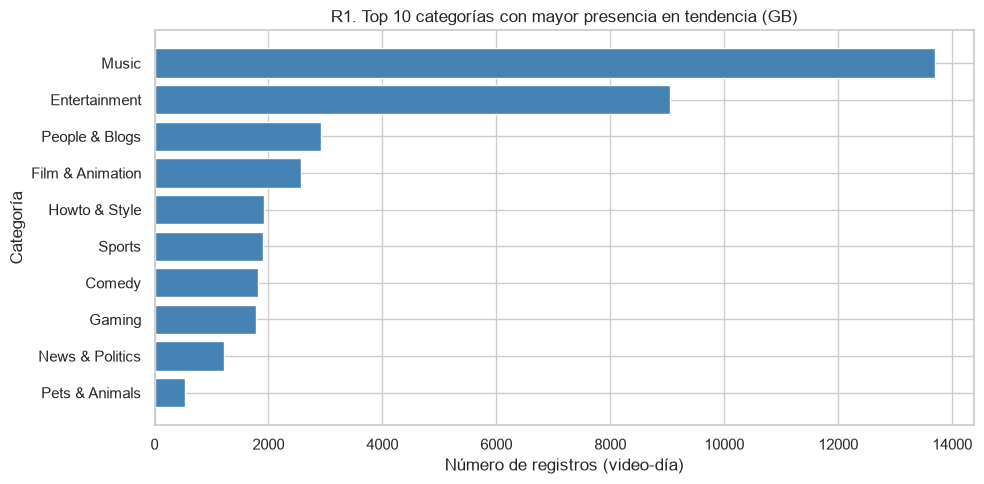


=== R2: Likes y Dislikes acumulados por categoría (Top 5 y Bottom 5) ===
Top 5:
                       likes  dislikes
category_name                        
Music             222811854   9310093
Entertainment      53952177   6595793
Comedy             12473647    447321
People & Blogs      9372239    791589
Film & Animation    7776471    417274
Bottom 5:
                     likes  dislikes
category_name                      
Education         1023585     41826
Pets & Animals     926734     22345
Autos & Vehicles   349318     24374
Travel & Events     97076      3843
Shows               44588       360


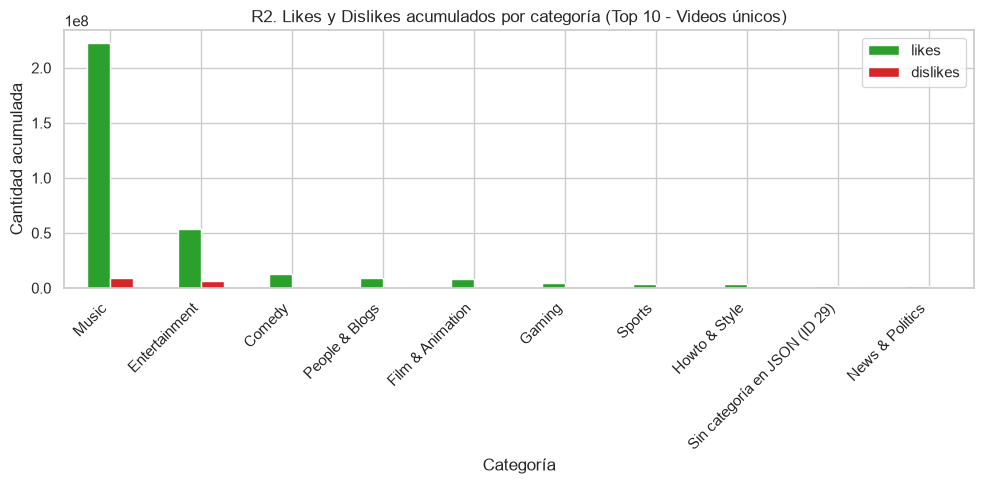


=== R3: Proporción más favorable (Top 5 y Bottom 5) ===
                               videos  aprobacion_pct  ratio_like_dislike
category_name                                                            
Shows                               1           99.20              123.86
Pets & Animals                     41           97.65               41.47
Howto & Style                     190           96.77               29.97
Comedy                            205           96.54               27.89
Gaming                            171           96.19               25.25
Travel & Events                    10           96.19               25.26
Education                          37           96.07               24.47
Music                             875           95.99               23.93
Science & Technology               41           95.07               19.27
Film & Animation                  193           94.91               18.64
Autos & Vehicles                   14           93.48  

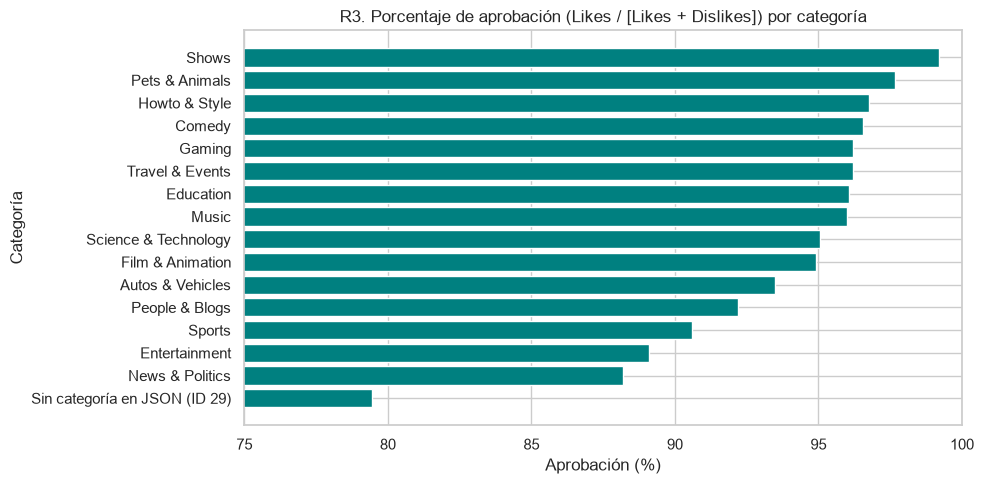


=== R4: Comentarios por cada 1,000 vistas por categoría (Top 8) ===
                               videos  com_por_1k_vistas_global  \
category_name                                                     
Sin categoría en JSON (ID 29)       6                     23.42   
News & Politics                   123                      6.69   
Howto & Style                     190                      5.26   
People & Blogs                    279                      4.27   
Gaming                            168                      3.93   
Entertainment                     833                      3.91   
Science & Technology               40                      3.66   
Education                          36                      3.55   

                               mediana_com_1k  
category_name                                  
Sin categoría en JSON (ID 29)        5.825409  
News & Politics                      6.577406  
Howto & Style                        3.029522  
People & Blogs      

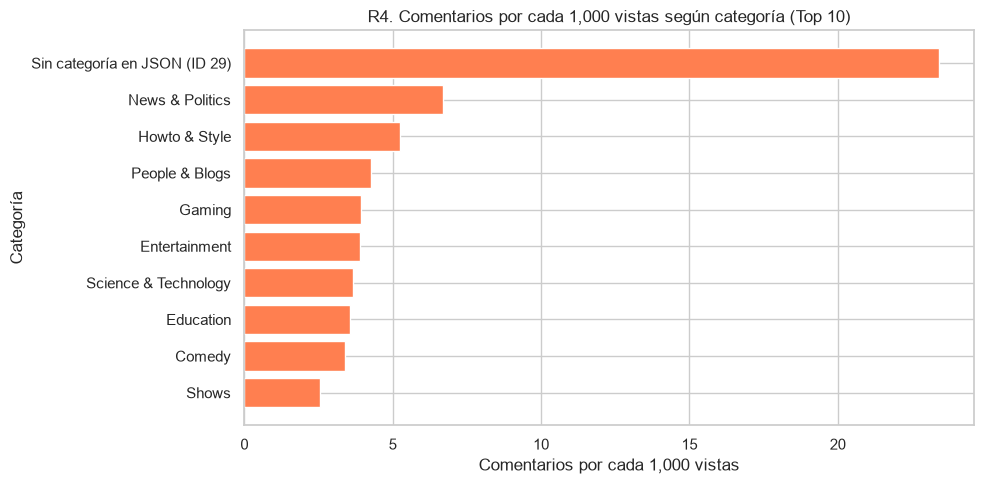

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Base de videos únicos (último día en tendencia de cada video para evitar doble conteo)
df_unique = (
    df_clean.sort_values(["video_id", "trending_date"])
    .drop_duplicates(subset=["video_id"], keep="last")
    .reset_index(drop=True)
)
print(f"Base registros: {len(df_clean):,} | Base videos únicos: {len(df_unique):,}\n")

# --- R1: Categorías con mayor presencia en tendencia ---
r1 = df_clean.groupby("category_name").agg(
    registros=("video_id", "count"),
    videos_unicos=("video_id", "nunique")
).sort_values("registros", ascending=False)
r1["pct_registros"] = (r1["registros"] / len(df_clean) * 100).round(2)
print("=== R1: Top 8 categorías por presencia ===")
print(r1.head(8))

fig, ax = plt.subplots()
top_r1 = r1.head(10).sort_values("registros")
ax.barh(top_r1.index, top_r1["registros"], color="steelblue")
ax.set_title("R1. Top 10 categorías con mayor presencia en tendencia (GB)")
ax.set_xlabel("Número de registros (video-día)")
ax.set_ylabel("Categoría")
plt.tight_layout()
plt.show()

# --- R2: Categorías con mayor y menor cantidad de likes y dislikes (videos únicos) ---
r2 = df_unique.groupby("category_name")[["likes", "dislikes"]].sum().sort_values("likes", ascending=False)
print("\n=== R2: Likes y Dislikes acumulados por categoría (Top 5 y Bottom 5) ===")
print("Top 5:\n", r2.head(5))
print("Bottom 5:\n", r2.tail(5))

fig, ax = plt.subplots()
r2.head(10).plot(kind="bar", ax=ax, color=["#2ca02c", "#d62728"])
ax.set_title("R2. Likes y Dislikes acumulados por categoría (Top 10 - Videos únicos)")
ax.set_xlabel("Categoría")
ax.set_ylabel("Cantidad acumulada")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# --- R3: Proporción más favorable entre likes y dislikes ---
# Indicador: % de aprobación = likes / (likes + dislikes).
r3_base = df_unique[(~df_unique["ratings_disabled"]) & ((df_unique["likes"] + df_unique["dislikes"]) > 0)]
r3 = r3_base.groupby("category_name").agg(
    videos=("video_id", "count"),
    likes_tot=("likes", "sum"),
    dislikes_tot=("dislikes", "sum")
)
r3["aprobacion_pct"] = (r3["likes_tot"] / (r3["likes_tot"] + r3["dislikes_tot"]) * 100).round(2)
r3["ratio_like_dislike"] = np.where(r3["dislikes_tot"] > 0, (r3["likes_tot"] / r3["dislikes_tot"]).round(2), np.nan)
r3 = r3.sort_values("aprobacion_pct", ascending=False)
print("\n=== R3: Proporción más favorable (Top 5 y Bottom 5) ===")
print(r3[["videos", "aprobacion_pct", "ratio_like_dislike"]])

fig, ax = plt.subplots()
r3_plot = r3.sort_values("aprobacion_pct")
ax.barh(r3_plot.index, r3_plot["aprobacion_pct"], color="teal")
ax.set_title("R3. Porcentaje de aprobación (Likes / [Likes + Dislikes]) por categoría")
ax.set_xlabel("Aprobación (%)")
ax.set_ylabel("Categoría")
ax.set_xlim(75, 100)
plt.tight_layout()
plt.show()

# --- R4: Relación entre vistas y comentarios entre categorías ---
# Indicador: Comentarios por cada 1,000 vistas 
r4_base = df_unique[(~df_unique["comments_disabled"]) & (df_unique["views"] > 0)]
r4 = r4_base.groupby("category_name").agg(
    videos=("video_id", "count"),
    views_tot=("views", "sum"),
    comments_tot=("comment_count", "sum"),
    mediana_com_1k=("comments_per_1k_views", "median")
)
r4["com_por_1k_vistas_global"] = (r4["comments_tot"] / r4["views_tot"] * 1000).round(2)
r4 = r4.sort_values("com_por_1k_vistas_global", ascending=False)
print("\n=== R4: Comentarios por cada 1,000 vistas por categoría (Top 8) ===")
print(r4[["videos", "com_por_1k_vistas_global", "mediana_com_1k"]].head(8))

fig, ax = plt.subplots()
r4_plot = r4.head(10).sort_values("com_por_1k_vistas_global")
ax.barh(r4_plot.index, r4_plot["com_por_1k_vistas_global"], color="coral")
ax.set_title("R4. Comentarios por cada 1,000 vistas según categoría (Top 10)")
ax.set_xlabel("Comentarios por cada 1,000 vistas")
ax.set_ylabel("Categoría")
plt.tight_layout()
plt.show()

Celda 5: Requerimientos R5 a R9

=== R5: Evolución mensual ===
            registros  videos_unicos
year_month                          
2017-11          3398            566
2017-12          6195            778
2018-01          5797            815
2018-02          5581            611
2018-03          6116            552
2018-04          4417            467
2018-05          4888            477
2018-06          2350            313


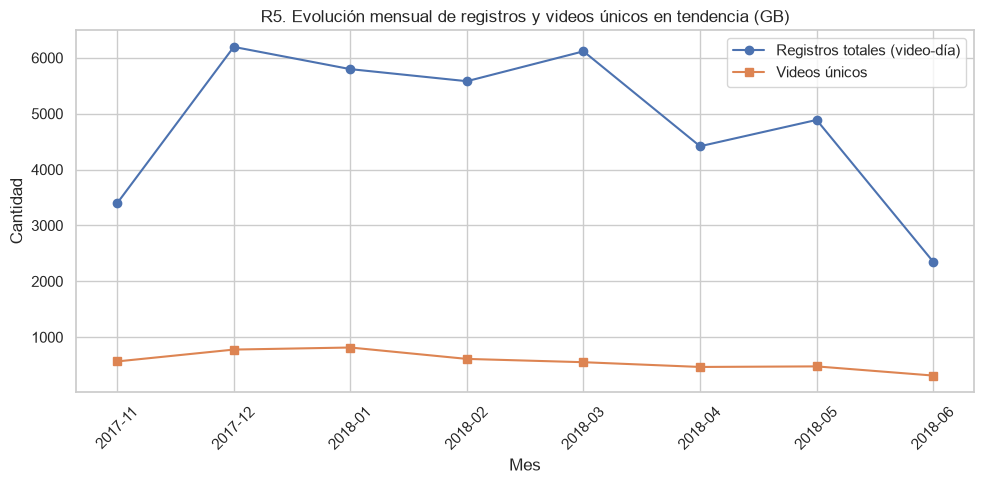


=== R6: Top 10 canales con mayor frecuencia ===
channel_title
The Tonight Show Starring Jimmy Fallon    205
TheEllenShow                              205
Jimmy Kimmel Live                         204
Saturday Night Live                       203
WWE                                       202
The Late Late Show with James Corden      199
Breakfast Club Power 105.1 FM             191
Late Night with Seth Meyers               191
The Late Show with Stephen Colbert        187
Netflix                                   184
Name: count, dtype: int64

Canales con menor frecuencia (aparecen exactamente 1 vez): 63 canales
Ejemplos de canales con 1 registro: ['Pop Blast', 'MadisonBeerMusicVEVO', 'AT&T', 'MILCK', 'Cute Girl Videos']


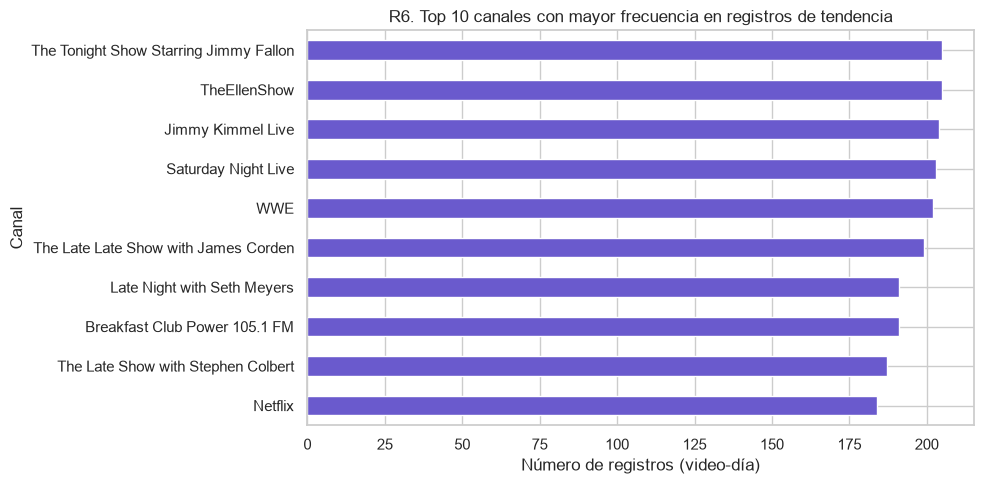


=== R7: Top 5 Estados por Vistas [DATOS SIMULADOS] ===
                       views      likes  dislikes
state                                            
Southampton       5569414543  115395725   8616799
Aberdeen          5481002679  117223647   7660093
Stockton On Tees  5448251927  107631361   5320879
South Yorkshire   5415152514  131798769   8433410
West Midlands     5367888073  121570676   7365316


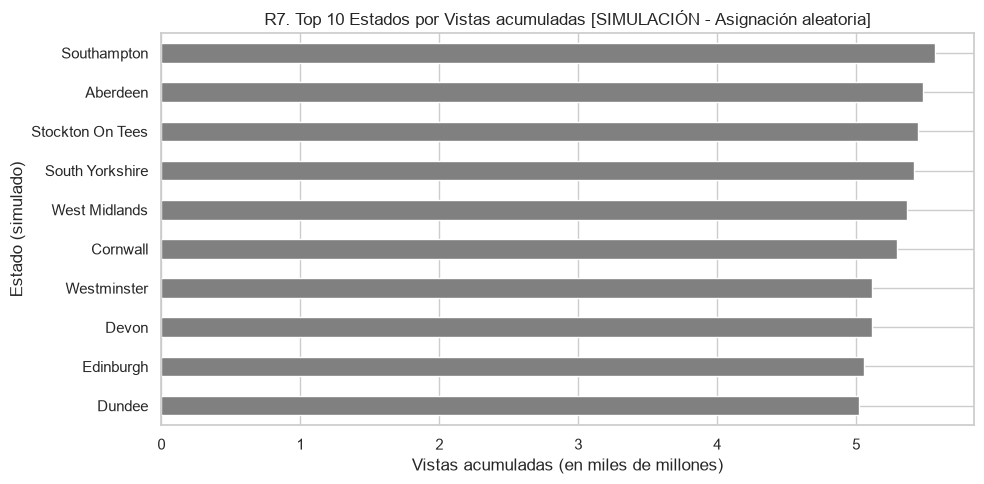


=== R8: Correlación Views vs Comment Count (n=3,216) ===
Pearson: 0.4344 | Spearman: 0.8433


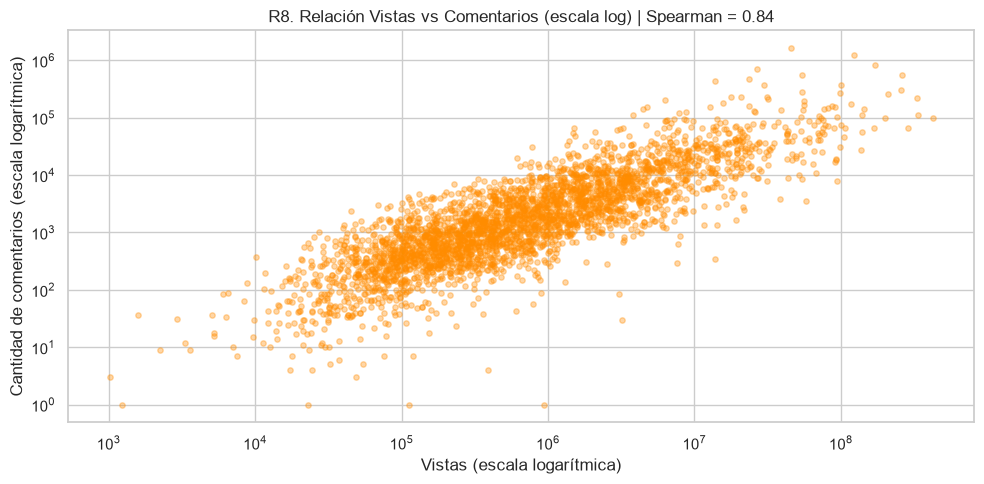


=== R9: Desempeño según día de publicación ===
                   videos_unicos  mediana_vistas  mediana_dias_a_tendencia
publish_dayofweek                                                         
Monday                       484        577139.5                      13.0
Tuesday                      521        658476.0                      13.0
Wednesday                    622        511593.0                      13.0
Thursday                     574        732847.5                      14.0
Friday                       616        777061.0                      13.0
Saturday                     188        346555.0                      13.0
Sunday                       267        320510.0                      11.0


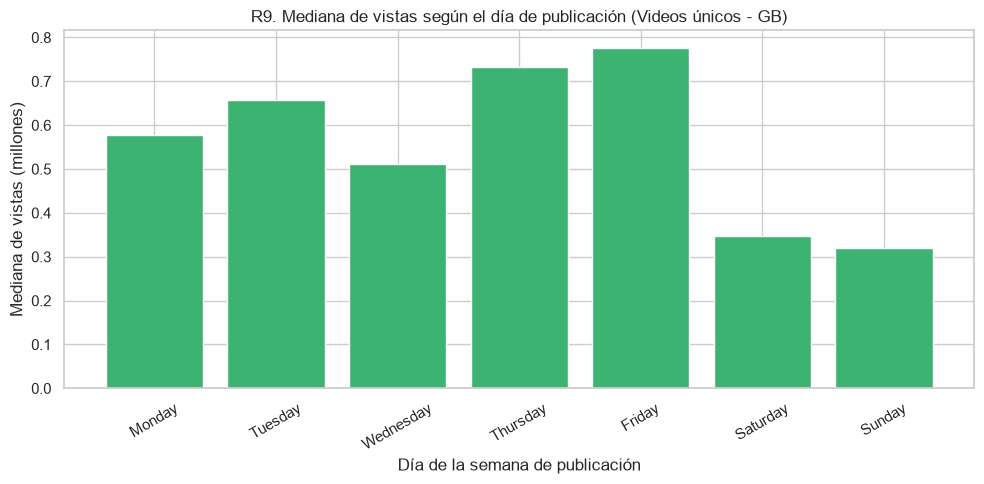

In [ ]:
# --- R5: Evolución de registros y videos únicos en el tiempo (por mes) ---
df_clean["year_month"] = df_clean["trending_date"].dt.to_period("M").astype(str)
r5 = df_clean.groupby("year_month").agg(
    registros=("video_id", "count"),
    videos_unicos=("video_id", "nunique")
)
print("=== R5: Evolución mensual ===")
print(r5)

fig, ax = plt.subplots()
ax.plot(r5.index, r5["registros"], marker="o", label="Registros totales (video-día)")
ax.plot(r5.index, r5["videos_unicos"], marker="s", label="Videos únicos")
ax.set_title("R5. Evolución mensual de registros y videos únicos en tendencia (GB)")
ax.set_xlabel("Mes")
ax.set_ylabel("Cantidad")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- R6: Canales con mayor y menor frecuencia en los registros ---
r6 = df_clean["channel_title"].value_counts()
print("\n=== R6: Top 10 canales con mayor frecuencia ===")
print(r6.head(10))
print(f"\nCanales con menor frecuencia (aparecen exactamente 1 vez): {(r6 == 1).sum():,} canales")
print("Ejemplos de canales con 1 registro:", r6[r6 == 1].index[:5].tolist())

fig, ax = plt.subplots()
r6.head(10).sort_values().plot(kind="barh", ax=ax, color="slateblue")
ax.set_title("R6. Top 10 canales con mayor frecuencia en registros de tendencia")
ax.set_xlabel("Número de registros (video-día)")
ax.set_ylabel("Canal")
plt.tight_layout()
plt.show()

# --- R7: Vistas, Likes y Dislikes por Estado (GEOGRAFÍA SIMULADA) ---
r7 = df_clean.groupby("state")[["views", "likes", "dislikes"]].sum().sort_values("views", ascending=False)
print("\n=== R7: Top 5 Estados por Vistas [DATOS SIMULADOS] ===")
print(r7.head(5))

fig, ax = plt.subplots()
(r7.head(10)["views"] / 1e9).sort_values().plot(kind="barh", ax=ax, color="gray")
ax.set_title("R7. Top 10 Estados por Vistas acumuladas [SIMULACIÓN - Asignación aleatoria]")
ax.set_xlabel("Vistas acumuladas (en miles de millones)")
ax.set_ylabel("Estado (simulado)")
plt.tight_layout()
plt.show()

# --- R8: Relación entre vistas y cantidad de comentarios (videos únicos) ---
r8_base = df_unique[(~df_unique["comments_disabled"]) & (df_unique["views"] > 0) & (df_unique["comment_count"] > 0)]
corr_pearson = r8_base["views"].corr(r8_base["comment_count"], method="pearson")
corr_spearman = r8_base["views"].corr(r8_base["comment_count"], method="spearman")
print(f"\n=== R8: Correlación Views vs Comment Count (n={len(r8_base):,}) ===")
print(f"Pearson: {corr_pearson:.4f} | Spearman: {corr_spearman:.4f}")

fig, ax = plt.subplots()
ax.scatter(r8_base["views"], r8_base["comment_count"], alpha=0.35, s=15, color="darkorange")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title(f"R8. Relación Vistas vs Comentarios (escala log) | Spearman = {corr_spearman:.2f}")
ax.set_xlabel("Vistas (escala logarítmica)")
ax.set_ylabel("Cantidad de comentarios (escala logarítmica)")
plt.tight_layout()
plt.show()

# --- R9 (Pregunta adicional): ¿Qué día de la semana conviene publicar para maximizar vistas? ---
orden_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
r9 = df_unique.groupby("publish_dayofweek").agg(
    videos_unicos=("video_id", "count"),
    mediana_vistas=("views", "median"),
    mediana_dias_a_tendencia=("days_to_trend", "median")
).reindex(orden_dias)
print("\n=== R9: Desempeño según día de publicación ===")
print(r9)

fig, ax = plt.subplots()
ax.bar(r9.index, r9["mediana_vistas"] / 1e6, color="mediumseagreen")
ax.set_title("R9. Mediana de vistas según el día de publicación (Videos únicos - GB)")
ax.set_xlabel("Día de la semana de publicación")
ax.set_ylabel("Mediana de vistas (millones)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Celda 6: Parte 5 – Modelado y evaluación predictiva

=== PLAN DE PRUEBA ===
Total videos únicos: 3,272 | Train: 2,617 (80%) | Test: 655 (20%)

=== EVALUACIÓN EN CONJUNTO DE PRUEBA (PARTE 5.5) ===
                  Modelo  R2 (log)  RMSE (log)  MAE (log)  R2 (original)  MAE (vistas)  RMSE (vistas)
Regresión Lineal (Ridge)    0.4159      1.4635     1.1695     -2974.2912    43360978.0    862119079.0
 Random Forest Regressor    0.9035      0.5949     0.4433         0.8278     1672373.0      6558181.0


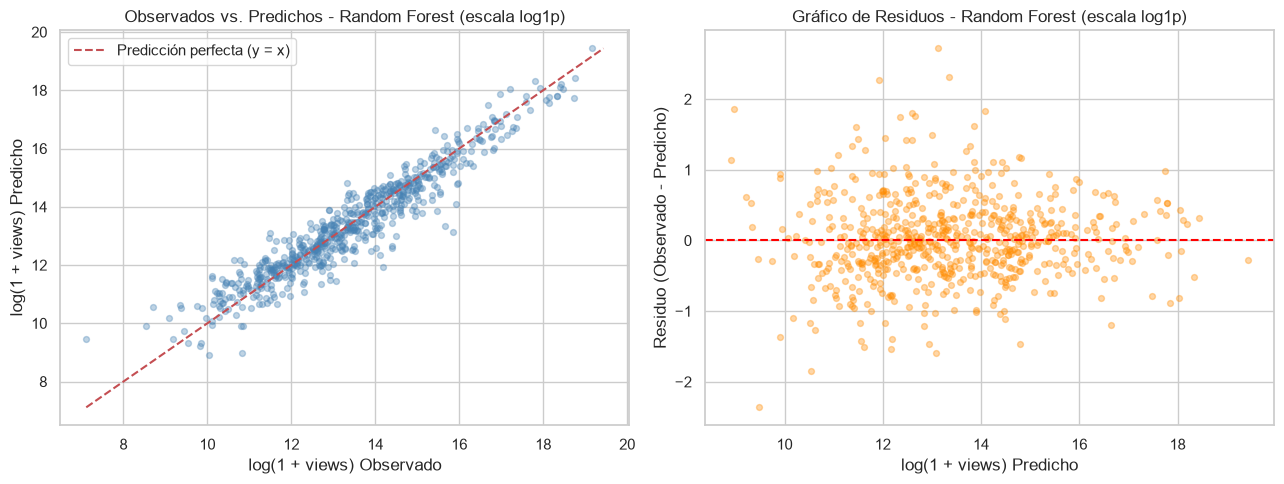

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

features_num = ["likes", "dislikes", "comment_count", "days_to_trend", "publish_hour", "title_length", "tag_count"]
features_cat = ["category_name", "publish_dayofweek", "comments_disabled", "ratings_disabled"]

df_model = df_unique[features_num + features_cat + ["views"]].dropna().copy()

X = df_model[features_num + features_cat]
y_log = np.log1p(df_model["views"])  

# 2. Plan de prueba (80% entrenamiento / 20% prueba, semilla fija = 42)
X_train, X_test, y_train_log, y_test_log = train_test_split(
    X, y_log, test_size=0.20, random_state=42
)
print(f"=== PLAN DE PRUEBA ===")
print(f"Total videos únicos: {len(df_model):,} | Train: {len(X_train):,} (80%) | Test: {len(X_test):,} (20%)\n")

# 3. Preprocesamiento 
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), features_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), features_cat),
    ]
)

# 4. Comparación de 2 modelos: Regresión Lineal (Ridge) vs Random Forest
modelos = {
    "Regresión Lineal (Ridge)": Ridge(alpha=1.0, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
}

resultados = []
predicciones_test = {}

for nombre, modelo in modelos.items():
    pipe = Pipeline([("prep", preprocessor), ("model", modelo)])
    pipe.fit(X_train, y_train_log)
    
    y_pred_log = pipe.predict(X_test)
    y_test_orig = np.expm1(y_test_log)
    y_pred_orig = np.expm1(y_pred_log)
    
    predicciones_test[nombre] = (y_test_log, y_pred_log, y_test_orig, y_pred_orig)
    
    resultados.append({
        "Modelo": nombre,
        "R2 (log)": round(r2_score(y_test_log, y_pred_log), 4),
        "RMSE (log)": round(root_mean_squared_error(y_test_log, y_pred_log), 4),
        "MAE (log)": round(mean_absolute_error(y_test_log, y_pred_log), 4),
        "R2 (original)": round(r2_score(y_test_orig, y_pred_orig), 4),
        "MAE (vistas)": round(mean_absolute_error(y_test_orig, y_pred_orig), 0),
        "RMSE (vistas)": round(root_mean_squared_error(y_test_orig, y_pred_orig), 0),
    })

df_res = pd.DataFrame(resultados)
print("=== EVALUACIÓN EN CONJUNTO DE PRUEBA ===")
print(df_res.to_string(index=False))

# 5. Gráficos diagnósticos del mejor modelo (Random Forest)
y_tl, y_pl, y_to, y_po = predicciones_test["Random Forest Regressor"]
residuos_log = y_tl - y_pl

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico 1: Observados vs Predichos 
axes[0].scatter(y_tl, y_pl, alpha=0.35, s=18, color="steelblue")
lims = [min(y_tl.min(), y_pl.min()), max(y_tl.max(), y_pl.max())]
axes[0].plot(lims, lims, "r--", lw=1.5, label="Predicción perfecta (y = x)")
axes[0].set_title("Observados vs. Predichos - Random Forest (escala log1p)")
axes[0].set_xlabel("log(1 + views) Observado")
axes[0].set_ylabel("log(1 + views) Predicho")
axes[0].legend()

# Gráfico 2: Residuos vs Predichos 
axes[1].scatter(y_pl, residuos_log, alpha=0.35, s=18, color="darkorange")
axes[1].axhline(0, color="red", linestyle="--", lw=1.5)
axes[1].set_title("Gráfico de Residuos - Random Forest (escala log1p)")
axes[1].set_xlabel("log(1 + views) Predicho")
axes[1].set_ylabel("Residuo (Observado - Predicho)")

plt.tight_layout()
plt.show()